# Part 3 – Joining model

**Question.** How does the chance that a non-member joins depend on the price they are offered? This model gives the tool its joining curve, $j(p)$.

**Why a model instead of raw join rates by season.** Raw rates by season and price are clean, since depth is randomized, but each season tested only five prices: \$10–\$14 before the cut and \$7–\$11 after. A scenario such as \$5 off a \$12 base in a season like 2018 has no raw rate. The model takes the price response from the randomized depths and each season's level from its ad exposure, so it covers every price in any reference season. Where raw rates exist, it matches them (within 0.33 pp by price and 0.13 pp by season; section 4).

**Findings** (details and checks below):

* **Price and ad exposure drive joining together.** At \$12, 0.5% of prospects with no exposure that season join, against 71% with heavy exposure (81–200 listens × impressions).

* **Each \$1 off raises the log-odds of joining by 0.90 at \$12** (1.21 at \$15, 0.40 at \$7), holding exposure fixed. The slope comes only from randomized depths, and exposure is balanced across them.

* **One price curve fits every season.** With exposure in the model, the slope at \$12 is −0.85 to −1.01 in every season and season effects add almost nothing. Without exposure it ranges from −0.17 to −0.91.

* **It holds out of time.** Fit on earlier seasons only, the model predicts spring and summer 2019 within 1.2 pp at every price, including \$7–\$9, which it had never seen.

* **Limitation: it doesn't forecast a season's level.** That depends on ad exposure, which isn't known in advance (fall 2019 comes out 2.6–4.3 pp low). The tool takes the ad environment as a stated scenario: a past season to resemble.

---

In [13]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

import os, sys
if Path.cwd().name == 'analysis':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import helper.utils as u

u.apply_style()
CUT = u.CUT_T                                        # spring 2019
BLUE, ORANGE = '#2a78d6', '#eb6834'

panel = u.load_panel(
    'data/customer_panel.csv',
    extra_cols=('customer_id', 'discount_flag', 'social_ad_impressions', 'podcast_ad_listen'))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Sample

* **Unit.** One row per customer and season, for customers in the five cut regions who were **not members the season before**. `joined` = 1 if they are a member this season.
* **Exposure.** `pod` is the customer's podcast ad listens this season and `soc` their social ad impressions.
* **Returning ex-members** are kept, so people who cancel can rejoin.

In [14]:
df = panel.sort_values(['customer_id', 't']).reset_index(drop=True)
df['prev_member'] = df.groupby('customer_id')['sign_up_flag'].shift(1)

keep = df['region_name'].ne(u.CONTROL) & df['prev_member'].eq(0)

d = (df[keep].rename(
    columns={
        'sign_up_flag': 'joined', 
        'membership_price': 'price', 
        'discount_flag': 'offer',
        'podcast_ad_listen': 'pod', 
        'social_ad_impressions': 'soc'
        }).reset_index(drop=True))

d['post'] = d['t'].ge(CUT).astype(int)
d['depth'] = np.where(d['offer'].eq(1), np.where(d['post'].eq(1), 12, 15) - d['price'], 0)      # $ off the base price

d = u.add_terms_join(d)
print(
    f"{len(d):,} rows, {d['customer_id'].nunique():,} customers, joining rate {d['joined'].mean():.1%}, {d['offer'].mean():.0%} offered")

# Check the price menu: offered = base - $1...$5; not offered = base ($15, then $12 from spring 2019)
display(d.groupby(['post', 'offer', 'price'])['joined'].agg(
    rows='size', 
    join_rate='mean').reset_index().round(4))

exposure = df[['customer_id', 't', 'podcast_ad_listen', 'social_ad_impressions']].rename(
    columns={'podcast_ad_listen': 'pod', 'social_ad_impressions': 'soc'})

3,346,845 rows, 356,806 customers, joining rate 6.1%, 25% offered


,post,offer,price,rows,join_rate
0,0,0,15,1907008,0.0346
1,0,1,10,127400,0.1733
2,0,1,11,127002,0.1349
3,0,1,12,127930,0.1005
4,0,1,13,127379,0.0744
5,0,1,14,126934,0.0527
6,1,0,12,602384,0.0598
7,1,1,7,40036,0.2522
8,1,1,8,40376,0.2042
9,1,1,9,40308,0.1572


### 1.1 Why not rely on the randomized depths alone?

Among offered prospects the discount depth is randomized, so comparing joining across depths is a clean experiment. The question is whether that comparison is enough for the tool.

In [15]:
# 1.1 What the randomized depths show on their own
#     (a) joining by price in each period, with the ad exposure of the same prospects
by_price = (d.assign(period=np.where(d['post'].eq(1), 'post-cut', 'pre-cut'),
                     any_exposure=d['pod_soc'].gt(0))
             .groupby(['period', 'offer', 'price'], sort=False)
             .agg(prospects=('joined', 'size'), join_pct=('joined', 'mean'), any_exposure_pct=('any_exposure', 'mean')))
by_price[['join_pct', 'any_exposure_pct']] *= 100
display(by_price.round(1).reset_index().sort_values(['price', 'period']))

#     (b) the same discount in different seasons: joining at $5 off, season by season
deepest = d[d['offer'].eq(1) & d['depth'].eq(5)].groupby('t').agg(price=('price', 'first'), join_pct=('joined', 'mean'),
                                                                   any_exposure_pct=('pod_soc', lambda s: s.gt(0).mean()))
deepest[['join_pct', 'any_exposure_pct']] *= 100
deepest.round(1).rename(index=u.period_label).T.rename_axis('$5 off')

,period,offer,price,prospects,join_pct,any_exposure_pct
5,post-cut,1,7,40036,25.2,23.6
10,post-cut,1,8,40376,20.4,23.6
8,post-cut,1,9,40308,15.7,23.8
6,post-cut,1,10,40177,12.1,24.1
2,pre-cut,1,10,127400,17.3,33.1
11,post-cut,1,11,39911,8.4,23.9
7,pre-cut,1,11,127002,13.5,33.3
4,post-cut,0,12,602384,6.0,23.6
0,pre-cut,1,12,127930,10.1,33.0
9,pre-cut,1,13,127379,7.4,33.1


t,Spr 2017,Sum 2017,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
$5 off,,,,,,,,,,,
price,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,7.0,7.0,7.0
join_pct,21.5,16.6,15.7,17.1,9.2,24.8,13.5,19.4,22.5,25.3,28.1
any_exposure_pct,37.8,35.2,34.5,32.5,30.1,35.1,28.0,30.1,23.4,24.7,22.7


**Reading**

* **Within a period the experiment is clean.** Joining rises with every \$1 off: 5.3% → 17.3% from \$14 to \$10 before the cut, and 8.4% → 25.2% from \$11 to \$7 after it.
* **Across periods the same price disagrees.** \$10 brings in 17.3% before the cut and 12.1% after, when fewer prospects saw ads (24% with any exposure, against 33%). Even within pre-cut seasons, \$5 off ranges from 9.2% to 24.8%.
* **No offered prospect paid full price**, so that point is a one-dollar extrapolation.
* **So** the randomized depths supply the price slope, and exposure carries each season's level.

## 2. Ad exposure belongs in the model

In [16]:
# 2.1 Joining rate (%) by price and this season's ad exposure
BANDS = [-1, 0, 25, 80, 200, np.inf]
BAND_LABELS = ['none', '1-25', '26-80', '81-200', 'over 200']
d['exposure_band'] = pd.cut(d['pod_soc'], BANDS, labels=BAND_LABELS)
by_band = (100 * d.pivot_table(index='exposure_band', columns='price', values='joined', observed=True)).round(1)
by_band.insert(0, '% of prospects', (100 * d['exposure_band'].value_counts(normalize=True)).round(1))
by_band.rename_axis('listens x impressions')

price,% of prospects,7,8,9,10,11,12,13,14,15
listens x impressions,,,,,,,,,,
none,69.2,14.3,9.8,5.8,3.1,1.3,0.5,0.1,0.0,0.0
1-25,10.2,35.5,27.7,20.1,12.2,6.5,2.6,0.8,0.2,0.0
26-80,11.5,65.3,58.5,48.3,38.1,25.9,14.8,7.0,2.6,0.5
81-200,7.6,96.6,95.6,92.5,88.4,81.5,70.6,57.2,39.6,22.4
over 200,1.4,100.0,100.0,100.0,100.0,100.0,100.0,99.7,98.7,95.3


In [17]:
# 2.2 Checking exposure balanced across the randomized depths
COV = ['pod', 'soc', 'pod_soc', 'sqrt_pod_soc', 'pod_zero', 'soc_zero']
smd = lambda a, b: (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
offered = d[d['offer'].eq(1)]
balance = pd.DataFrame([{'post': post, 'depth': k, **{c: smd(x.loc[x['depth'].eq(k), c], x.loc[x['depth'].ne(k), c])
                                                      for c in COV}}
                        for post, x in offered.groupby('post') for k in range(1, 6)]).set_index(['post', 'depth'])
print(f"Largest |SMD| across depths: {balance.abs().max().max():.3f}")
balance.round(3)


Largest |SMD| across depths: 0.009


pod    soc  pod_soc  sqrt_pod_soc  pod_zero  soc_zero
post depth                                                         
0    1     -0.001 -0.001   -0.002        -0.001    -0.001     0.005
     2     -0.001 -0.002   -0.003        -0.002     0.003    -0.003
     3      0.001 -0.001   -0.004        -0.004     0.003    -0.003
     4      0.001 -0.001    0.004         0.004    -0.006    -0.000
     5      0.000  0.004    0.005         0.003     0.001     0.001
1    1      0.004  0.002    0.003         0.004    -0.006     0.002
     2      0.008 -0.001    0.008         0.009    -0.009     0.007
     3     -0.008  0.008   -0.001        -0.001     0.008    -0.009
     4      0.000 -0.001   -0.001        -0.004     0.000     0.004
     5     -0.005 -0.009   -0.008        -0.008     0.007    -0.004

In [18]:
# 2.3 Reverse check: does joining raise exposure? Randomized depth instruments for joining
from statsmodels.sandbox.regression.gmm import IV2SLS
import statsmodels.api as sm

results = []

for period in [0, 1]:

    # Keep offered customers in this period
    g = d[(d['offer'] == 1) & (d['post'] == period)]

    # Control for season × region
    season_region = (
        g['t'].astype(str) + '_' + g['region_name'].astype(str)
    )
    controls = pd.get_dummies(
        season_region, drop_first=True, dtype=float
    )

    # Instrument: randomized discount depth
    discount = pd.get_dummies(
        g['depth'], drop_first=True, dtype=float
    )

    # Regression variables
    X = sm.add_constant(pd.concat([g[['joined']], controls], axis=1).astype(float))
    Z = sm.add_constant(pd.concat([discount, controls], axis=1))

    for outcome in ['pod', 'soc', 'pod_soc']:

        # IV estimate of joining's effect on exposure
        fit = IV2SLS(g[outcome].astype(float), X, Z).fit()

        effect = fit.params['joined']
        se = fit.bse['joined']

        # Observational difference
        gap = (
            g.loc[g['joined'] == 1, outcome].mean()
            - g.loc[g['joined'] == 0, outcome].mean()
        )

        results.append({
            'period': 'pre-cut' if period == 0 else 'post-cut',
            'outcome': outcome,
            'observed_gap': gap,
            'iv_effect': effect,
            'ci_low': effect - 1.96 * se,
            'ci_high': effect + 1.96 * se
        })

reverse_check = pd.DataFrame(results)
reverse_check.round(2)


,period,outcome,observed_gap,iv_effect,ci_low,ci_high
0,pre-cut,pod,13.54,0.05,-0.39,0.49
1,pre-cut,soc,2.85,0.11,-0.09,0.31
2,pre-cut,pod_soc,112.35,2.60,-0.12,5.31
3,post-cut,pod,7.42,-0.39,-0.82,0.04
4,post-cut,soc,1.63,-0.26,-0.53,0.00
5,post-cut,pod_soc,59.63,-3.10,-6.04,-0.16


**Reading**

* **Exposure separates joiners sharply.** At \$12, joining goes from 0.5% with no exposure (69% of prospects) to 71% at 81–200 listens × impressions, and is near 100% above 200.

* **It is balanced across depths** (largest standardized difference 0.009), so it doesn't bias the price slope.

* **Joining doesn't drive exposure.** With depth as the instrument, joining's effect on listens × impressions is +2.6 pre-cut and −3.1 post-cut, against observed joiner vs non-joiner gaps of 112 and 60.

## 3. Model design

$$\operatorname{logit} P(\text{join}_{it}) = \beta_1\,(\text{price}_{it}-12) + \beta_2\,(\text{price}_{it}-12)^2 + \gamma\,\text{offer}_{it} + f(\text{pod}_{it}, \text{soc}_{it}) + \alpha_{\text{region}}$$

* `price_j`, `price_sq`: the offered price minus \$12 and its square, so $\beta_1$ is the slope at today's \$12 base and the intercept is the log-odds at \$12.
* `offer`: whether a discount was offered. It absorbs any difference between offered and non-offered prospects, so the price terms are never estimated from that comparison, which follows a business rule.
* $f$: listens, impressions, their product and its square root, and flags for zero listens and zero impressions.
* Region fixed effects.

In [19]:
EXPOSURE = ['pod', 'soc', 'sqrt_pod_soc', 'pod_soc', 'pod_zero', 'soc_zero']
RHS = 'offer + ' + ' + '.join(EXPOSURE) + ' + C(region_name)'
FORMULA = 'joined ~ price_j + price_sq + ' + RHS

final = u.fit_logit(FORMULA, d)

# 3.1 Price shape: one dummy per price vs the quadratic
dummies = u.fit_logit('joined ~ C(price) + ' + RHS, d)
prices = np.arange(7, 16)
shape = pd.DataFrame({'price dummies': np.r_[0, dummies.params.filter(like='C(price)').to_numpy()],
                      'quadratic': final.params['price_j'] * (prices - 7)
                                   + final.params['price_sq'] * ((prices - 12) ** 2 - 25)}, index=prices)
del dummies
shape.round(2).T.rename_axis('log-odds vs $7', axis=1)

log-odds vs $7,7,8,9,10,11,12,13,14,15
price dummies,0.0,-0.44,-1.0,-1.69,-2.44,-3.27,-4.17,-5.19,-6.46
quadratic,-0.0,-0.45,-1.0,-1.65,-2.40,-3.26,-4.21,-5.27,-6.42


In [20]:
# 3.2 Does the season still matter once exposure is in the model?
#     (a) how much season effects add, with and without exposure; (b) what leaving them out costs
NO_EXPOSURE = 'joined ~ price_j + price_sq + offer + C(region_name)'
fits = {'without exposure': (u.fit_logit(NO_EXPOSURE, d), u.fit_logit(NO_EXPOSURE + ' + C(t)', d)),
        'with exposure': (final, u.fit_logit(FORMULA + ' + C(t)', d))}
season_test = pd.DataFrame({name: {'LR for season effects': 2 * (b.llf - a.llf),
                                   'df': b.df_model - a.df_model,
                                   'smallest effect': b.params.filter(like='C(t)').min(),
                                   'largest effect': b.params.filter(like='C(t)').max()}
                            for name, (a, b) in fits.items()}).T
with_t = fits['with exposure'][1]
print(f"Price slope at $12: {final.params['price_j']:.3f} without season effects, "
      f"{with_t.params['price_j']:.3f} with them")

by_t = (100 * d.assign(p_hat=final.predict(d), p_hat_t=with_t.predict(d))
              .groupby('t')[['joined', 'p_hat', 'p_hat_t']].mean())
by_t.columns = ['actual %', 'model %', 'model + season effects %']
by_t['gap pp'] = by_t['actual %'] - by_t['model %']
by_t.index = [u.period_label(k) for k in by_t.index]
print(f"Largest per-season gap without season effects: {by_t['gap pp'].abs().max():.2f} pp")
del fits, with_t
display(season_test.round(2))
by_t.round(2).T


# 3.3 Price slope by season, with and without exposure in the model (both with season effects)
seasons = sorted(d['t'].unique())
slope_terms = [f'price_t{k}' for k in seasons]
by_season = d.assign(**{f'price_t{k}': (d['price'] - 12) * d['t'].eq(k) for k in seasons})
no_exposure = u.fit_logit('joined ~ ' + ' + '.join(slope_terms) + ' + offer + C(region_name) + C(t)', by_season)
with_exposure = u.fit_logit(FORMULA.replace('price_j + ', ' + '.join(slope_terms) + ' + ') + ' + C(t)', by_season)
slopes = pd.DataFrame({'slope, no exposure terms': no_exposure.params[slope_terms].to_numpy(),
                       'slope at $12, exposure terms': with_exposure.params[slope_terms].to_numpy(),
                       'joining rate': d.groupby('t')['joined'].mean().to_numpy()},
                      index=[u.period_label(k) for k in seasons])
del no_exposure, with_exposure, by_season
slopes.round(3).T

Price slope at $12: -0.903 without season effects, -0.880 with them
Largest per-season gap without season effects: 0.13 pp


,LR for season effects,df,smallest effect,largest effect
without exposure,75872.35,10.0,-2.02,0.69
with exposure,111.16,10.0,-0.03,0.13


,Spr 2017,Sum 2017,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
"slope, no exposure terms",-0.322,-0.473,-0.442,-0.386,-0.906,-0.169,-0.524,-0.190,-0.518,-0.324,-0.173
"slope at $12, exposure terms",-0.882,-0.867,-0.852,-0.887,-1.013,-0.880,-0.871,-0.857,-0.900,-0.890,-0.898
joining rate,0.066,0.034,0.036,0.045,0.010,0.120,0.024,0.086,0.044,0.081,0.136


**Reading**

* **The quadratic matches one dummy per price** within 0.08 log-odds across \$7–\$15.

* **Season effects aren't needed.** With exposure they range from −0.03 to +0.13 log-odds (−2.02 to +0.69 without), and leaving them out misses no season by more than 0.13 pp.

* **The slope at \$12 is −0.85 to −1.01 in every season.** Without exposure it ranges from −0.17 to −0.91 and is flattest when joining is high, because each season mixes exposed and unexposed prospects differently.

## 4. Validation

In [21]:
terms = ['price_j', 'price_sq', 'offer', *EXPOSURE]
ci = final.conf_int()
display(pd.DataFrame({'estimate': final.params[terms], 'ci_low': ci.loc[terms, 0],
                      'ci_high': ci.loc[terms, 1], 'p_value': final.pvalues[terms]}).round(4))
slope_at = lambda p: final.params['price_j'] + 2 * final.params['price_sq'] * (p - 12)
print(f"Price slope, log-odds per $1: {slope_at(15):.2f} at $15, {slope_at(12):.2f} at $12, {slope_at(7):.2f} at $7")

,estimate,ci_low,ci_high,p_value
price_j,-0.9032,-0.9089,-0.8975,0.0000
price_sq,-0.0503,-0.0516,-0.0491,0.0000
offer,-0.0133,-0.0349,0.0083,0.2267
pod,0.0000,-0.0019,0.0020,0.9604
soc,-0.0319,-0.0360,-0.0279,0.0000
sqrt_pod_soc,0.0451,0.0350,0.0552,0.0000
pod_soc,0.0433,0.0426,0.0439,0.0000
pod_zero,-0.8590,-0.8984,-0.8195,0.0000
soc_zero,-0.0692,-0.1076,-0.0308,0.0004


Price slope, log-odds per $1: -1.21 at $15, -0.90 at $12, -0.40 at $7


In [22]:
# 4.1 Calibration: actual vs predicted joining rate at every price
d['p_hat'] = final.predict(d)
cal = d.groupby(['post', 'offer', 'price']).agg(rows=('joined', 'size'), actual=('joined', 'mean'),
                                                predicted=('p_hat', 'mean'))
cal['gap_pp'] = 100 * (cal['actual'] - cal['predicted'])
by_t = d.groupby('t').agg(actual=('joined', 'mean'), predicted=('p_hat', 'mean'))
print(f"Largest gap by price: {cal['gap_pp'].abs().max():.2f} pp; "
      f"by season: {100 * (by_t['actual'] - by_t['predicted']).abs().max():.2f} pp")
cal.round(4)

Largest gap by price: 0.33 pp; by season: 0.13 pp


rows  actual  predicted  gap_pp
post offer price                                    
0    0     15     1907008  0.0346     0.0348 -0.0127
     1     10      127400  0.1733     0.1766 -0.3283
           11      127002  0.1349     0.1361 -0.1228
           12      127930  0.1005     0.1006 -0.0111
           13      127379  0.0744     0.0732  0.1239
           14      126934  0.0527     0.0511  0.1555
1    0     12      602384  0.0598     0.0594  0.0402
     1     7        40036  0.2522     0.2510  0.1149
           8        40376  0.2042     0.2024  0.1785
           9        40308  0.1572     0.1561  0.1034
           10       40177  0.1207     0.1181  0.2555
           11       39911  0.0839     0.0846 -0.0732

In [23]:
# 4.2 Rolling-origin test: for each post-cut season, fit on every earlier season, then predict that one season.
#     No exposure from the predicted season is used. It is matched to the training season with the closest
#     planned podcast and social spend, and each prospect is given their own exposure from that season.
SEASON_ORDER = {'winter': 0, 'spring': 1, 'summer': 2, 'fall': 3}
spend = pd.read_csv('data/aggregate.csv')
spend['t'] = (spend['year'] - 2017) * 4 + spend['season'].map(SEASON_ORDER)
log_spend = np.log(spend.groupby('t')[['podcast_spend', 'social_spend']].first())

parts, origins = [], []
for k in sorted(d.loc[d['post'].eq(1), 't'].unique()):
    train = d[d['t'].lt(k)]
    m = u.match_season(k, sorted(train['t'].unique()), log_spend)
    fit = u.fit_logit(FORMULA, train)
    x = u.with_exposure_from(d[d['t'].eq(k)], m, exposure)
    x['predicted'] = fit.predict(x)
    x['new_price'] = ~x['price'].isin(train['price'].unique())                  # never offered in the training seasons
    parts.append(x[['t', 'depth', 'new_price', 'joined', 'predicted']].assign(matched=m))
    origins.append({'season': u.period_label(k), 'trained through': u.period_label(k - 1),
                    'matched season': u.period_label(m), 'slope at $12': fit.params['price_j'],
                    'price_sq': fit.params['price_sq']})
del fit, train, x
post = pd.concat(parts)

oot = post.groupby(['t', 'matched', 'depth']).agg(
    actual=('joined', 'mean'), 
    predicted=('predicted', 'mean'),
    new_price=('new_price', 'first'))
oot['gap_pp'] = 100 * (oot['actual'] - oot['predicted'])
origins = pd.DataFrame(origins).set_index('season')
origins['largest gap (pp)'] = oot['gap_pp'].abs().groupby(level='t').max().to_numpy()

display(origins.round(3))
((100 * oot[['actual', 'predicted']]).round(1).reset_index()
    .assign(t=lambda x: x['t'].map(u.period_label), matched=lambda x: x['matched'].map(u.period_label))
    .rename(columns={'matched': 'matched season', 'depth': 'price off ($)', 'actual': 'actual %', 'predicted': 'predicted %'}))

,trained through,matched season,slope at $12,price_sq,largest gap (pp)
season,,,,,
Spr 2019,Win 2019,Spr 2018,-0.882,-0.045,1.202
Sum 2019,Spr 2019,Sum 2017,-0.907,-0.049,1.089
Fall 2019,Sum 2019,Win 2019,-0.902,-0.050,4.304


,t,matched season,price off ($),actual %,predicted %
0,Spr 2019,Spr 2018,0,1.8,1.7
1,Spr 2019,Spr 2018,1,3.8,4.0
2,Spr 2019,Spr 2018,2,7.3,6.9
3,Spr 2019,Spr 2018,3,11.6,11.0
4,Spr 2019,Spr 2018,4,16.7,15.9
5,Spr 2019,Spr 2018,5,22.5,21.3
6,Sum 2019,Sum 2017,0,5.3,5.9
7,Sum 2019,Sum 2017,1,8.0,9.0
8,Sum 2019,Sum 2017,2,12.1,12.8
9,Sum 2019,Sum 2017,3,15.7,16.6


In [24]:
# 4.3 First-season revenue per offered prospect
rev = oot.drop(index=0, level='depth')[['actual', 'predicted']].copy()
rev = rev.mul(12 - rev.index.get_level_values('depth'), axis=0)
(rev.round(2).reset_index()
    .assign(t=lambda x: x['t'].map(u.period_label), matched=lambda x: x['matched'].map(u.period_label))
    .rename(columns={'matched': 'matched season', 'depth': 'price off ($)', 'actual': 'actual $ per prospect',
                     'predicted': 'predicted $ per prospect'}))

,t,matched season,price off ($),actual $ per prospect,predicted $ per prospect
0,Spr 2019,Spr 2018,1,0.42,0.44
1,Spr 2019,Spr 2018,2,0.73,0.69
2,Spr 2019,Spr 2018,3,1.04,0.99
3,Spr 2019,Spr 2018,4,1.33,1.27
4,Spr 2019,Spr 2018,5,1.57,1.49
5,Sum 2019,Sum 2017,1,0.88,0.99
6,Sum 2019,Sum 2017,2,1.21,1.28
7,Sum 2019,Sum 2017,3,1.41,1.49
8,Sum 2019,Sum 2017,4,1.67,1.72
9,Sum 2019,Sum 2017,5,1.77,1.85


**Reading**

*Coefficients*
* **Price:** −0.90 log-odds per \$1 at \$12 (−1.21 at \$15, −0.40 at \$7).
* **Being offered adds nothing beyond the price** (−0.01, p = 0.23).

*4.1 Calibration*
* Within 0.33 pp of actual joining at every price and 0.13 pp in every season, with no season effects.

*4.2 Rolling origin.* Each post-cut season is predicted from a model fit on earlier seasons, with exposure borrowed from the training season whose podcast and social spend was closest.
* **The price curve holds.** The squared term stays at −0.045 to −0.050, and spring 2019 is predicted within 1.2 pp at \$7–\$9, prices the model had never seen.
* **The level depends on the spend match.** Spring and summer 2019 are within 1.2 pp. Fall 2019, matched to winter 2019, is 2.6–4.3 pp low at every price: a level shift, not a different slope.

*4.3 Revenue*
* **The model picks the same discount as the data:** \$5 off is best in all three seasons, actual and predicted.

## 5. Final Visual

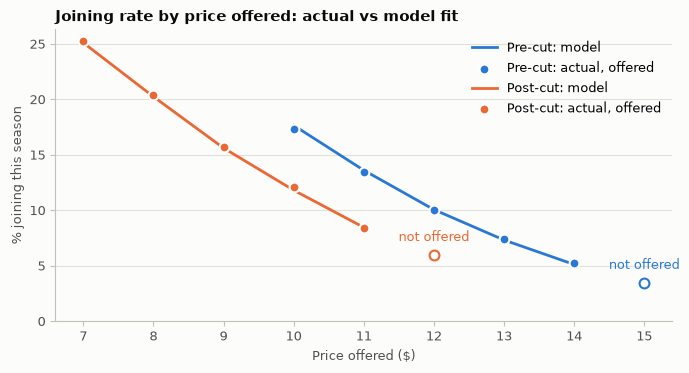

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (flag, name), color in zip([(0, 'Pre-cut'), (1, 'Post-cut')], [BLUE, ORANGE]):
    offers, base = cal.loc[(flag, 1)], cal.loc[(flag, 0)]
    ax.plot(offers.index, 100 * offers['predicted'], color=color, lw=2, label=f'{name}: model')
    ax.scatter(offers.index, 100 * offers['actual'], s=50, color=color, edgecolor='white', linewidth=1.5,
               zorder=3, label=f'{name}: actual, offered')
    ax.scatter(base.index, 100 * base['actual'], s=50, facecolor='white', edgecolor=color, linewidth=1.5, zorder=3)
    ax.annotate('not offered', (base.index[0], 100 * base['actual'].iloc[0]), xytext=(0, 10),
                textcoords='offset points', ha='center', color=color, fontsize=9)
ax.set_xticks(range(7, 16))
ax.set_ylim(0, None)
ax.set_xlabel('Price offered ($)')
ax.set_ylabel('% joining this season')
ax.set_title('Joining rate by price offered: actual vs model fit', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [26]:
out = Path('outputs')
out.mkdir(exist_ok=True)
final.params.rename('coefficient').to_csv(out / 'join_model_params.csv')
slopes.to_csv(out / 'join_price_slope_by_season.csv')